## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")



00: Importing torch...done; this took 0.00286ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.28s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.32s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_sqrtVar_vol_simple 1.1 [2d2edb96|acaee5f1ce9f88de] created.
00: Trainer for 'AEC train_sqrtVar_vol_simple 1.1 [2d2edb96|acaee5f1ce9f88de]' on data acaee5f1ce9f88de
00: ===================================================================================================
01:   Restoring checkpoint from '/media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_vol_simple 75c1566e/last.pt'... done; this took 0.07s.
01:   Model is ready. Current epoch to train is 33.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_vol_simple 75c1566e/.
00: Launching 'AEC train_sqrtVar_vol_simple 1.1 [2d2edb96|acaee5f1ce9f88de]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 10 batches per epoch, and a batch size of 2048 for valuation. The model has 43233 parameters. Resuming from epoch 33.
00: Training 'train_sqrtVar

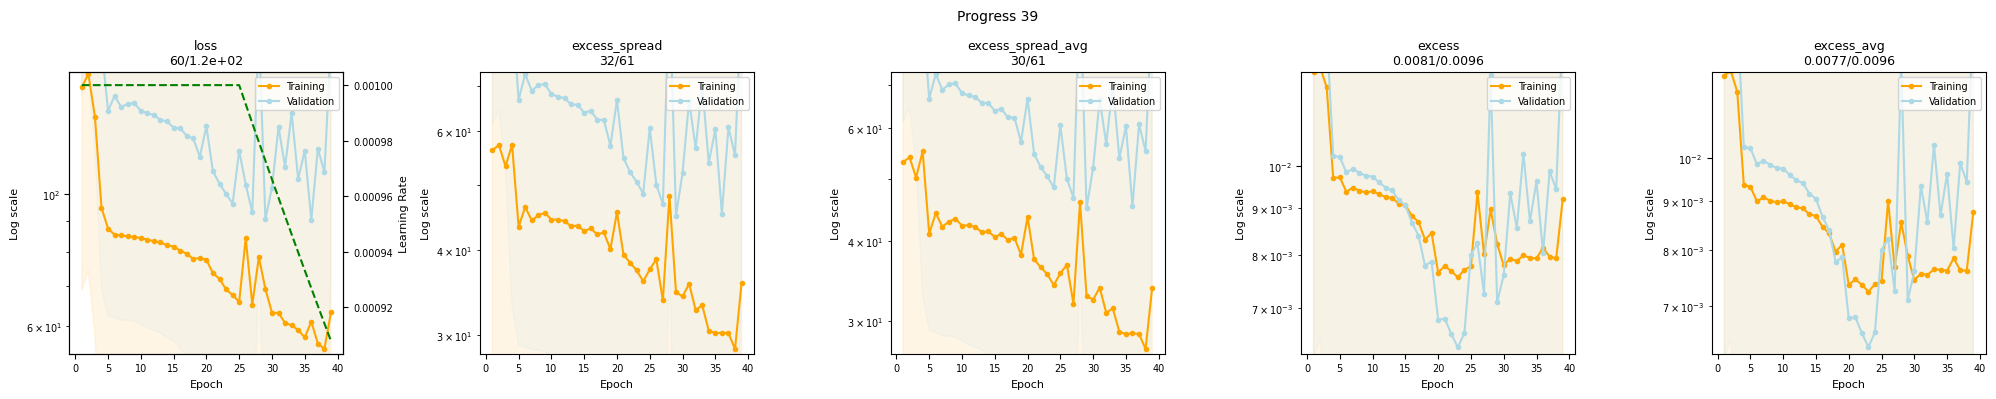

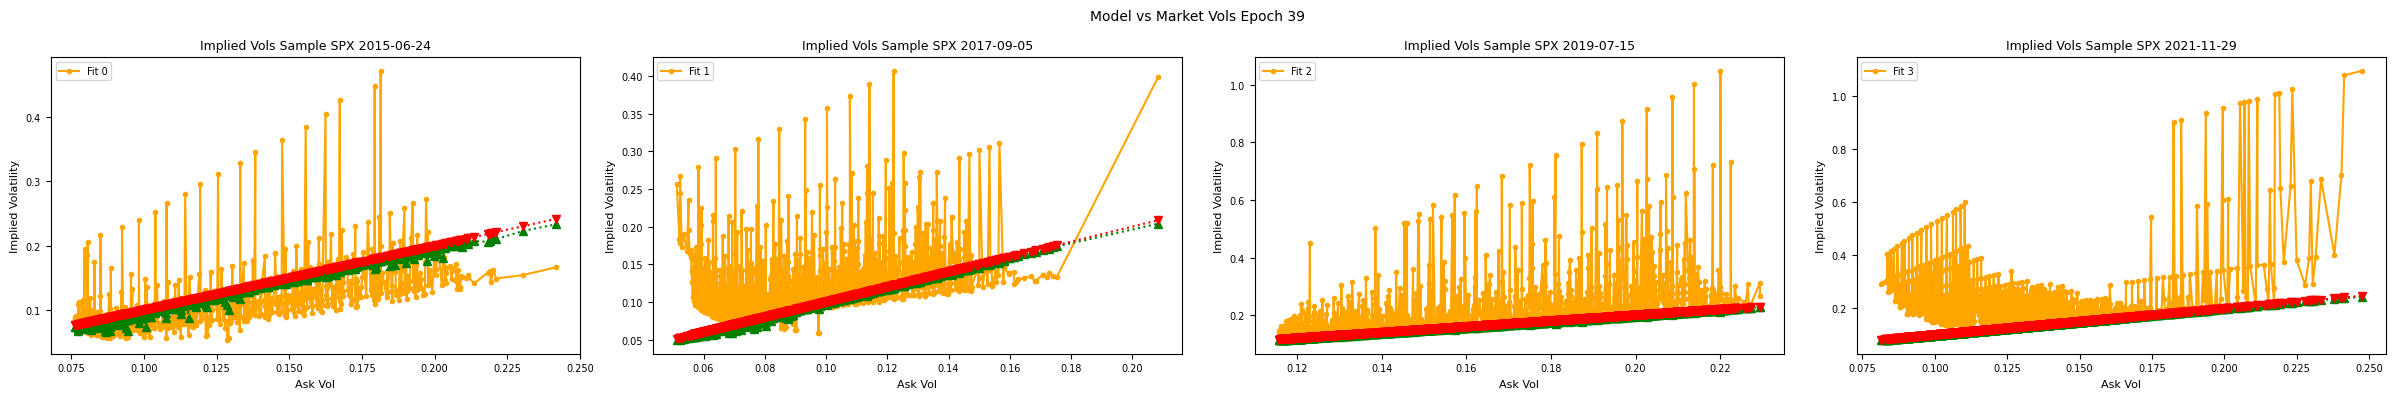

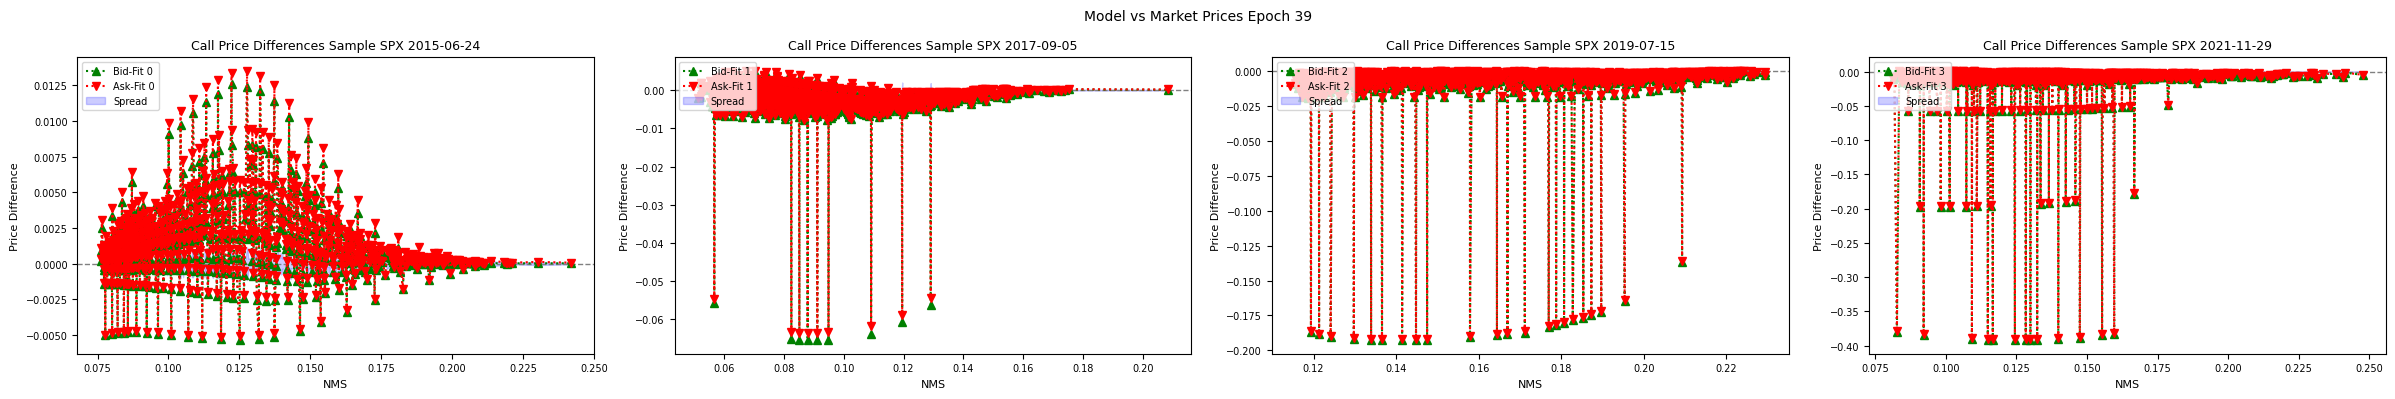

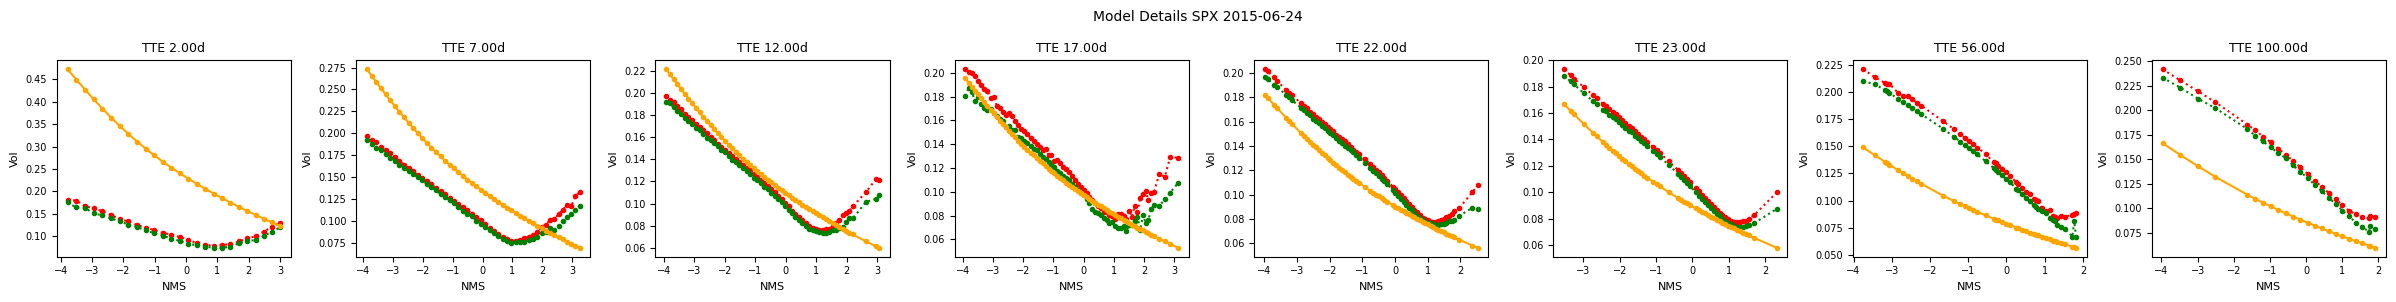

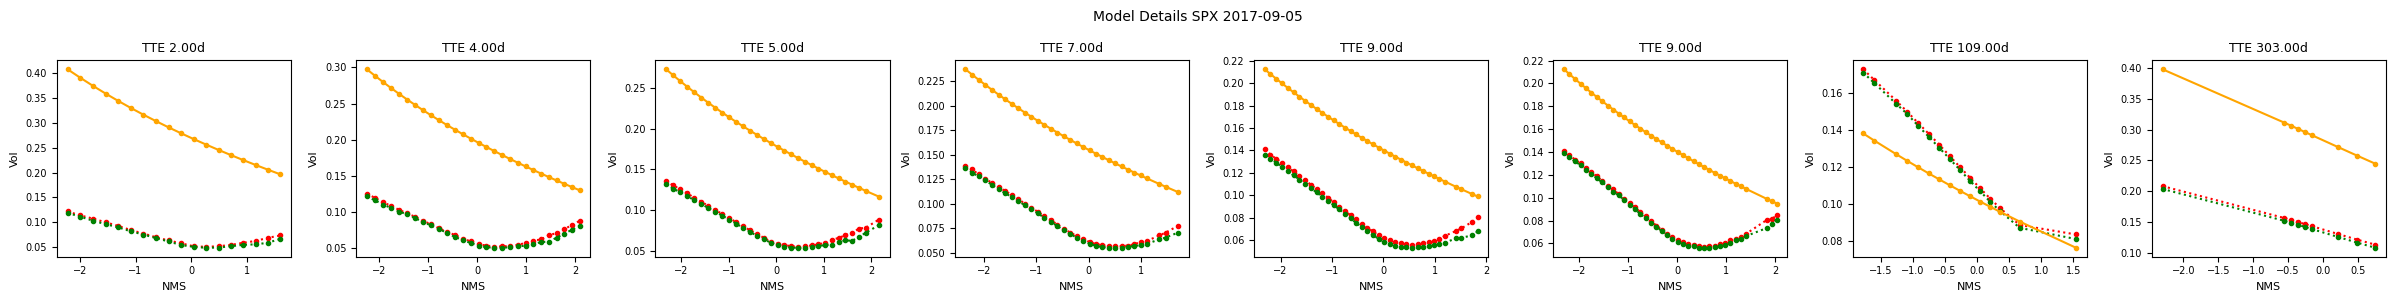

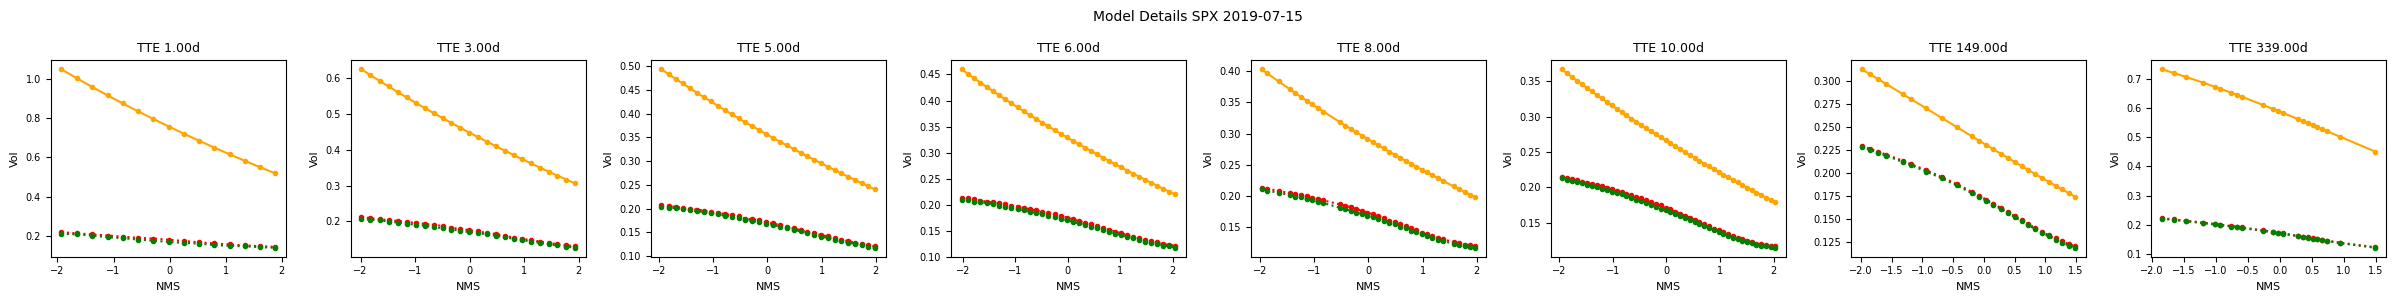

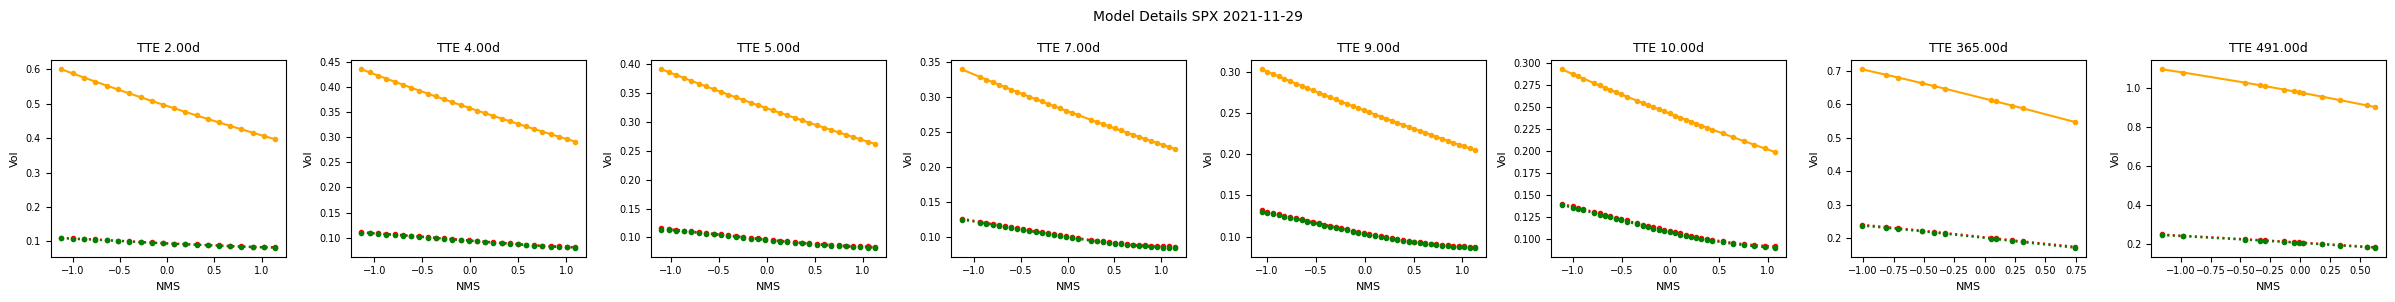

00: Training 'train_sqrtVar_vol_simple' epoch 35/1000 error avg trn 57.48; val 57.29/118.5 [5s 0.98s 0.24s]. LR: 9.33e-04, GN 28.76, excess_weighted: 5.066e-14/2.168e-13, excess_weighted_avg: 0.004224/0.005867, excess_spread: 30.19/60.38, excess_spread_avg: 28.67/60.38, excess: 0.007926/0.009624, excess_avg: 0.007616/0.009624. ETA: 4:09:01.
00: Training 'train_sqrtVar_vol_simple' epoch 36/1000 error avg trn 58.57; val 60.95/90.51 [4s 0.97s 0.24s]. LR: 9.27e-04, GN 71.02, excess_weighted: 5.072e-14/1.627e-13, excess_weighted_avg: 0.004411/0.004629, excess_spread: 30.23/45.3, excess_spread_avg: 28.75/45.3, excess: 0.008143/0.008039, excess_avg: 0.007846/0.008039. ETA: 6:18:50.
00: Training 'train_sqrtVar_vol_simple' epoch 37/1000 error avg trn 59.51; val 55.93/119.4 [4s 0.97s 0.24s]. LR: 9.20e-04, GN 66.78, excess_weighted: 5.069e-14/2.183e-13, excess_weighted_avg: 0.004111/0.005902, excess_spread: 30.21/60.8, excess_spread_avg: 28.68/60.8, excess: 0.007959/0.009876, excess_avg: 0.007626

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "sqrtVar",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,

    # rarely touch these
    weight_by_spread = True,

    encoder = DeepSetEncoderFactory(
        num_compress = 128,
        inside_tanh = True,
        set_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32,
            activation = 'Softplus',
        ),
        fix_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64,
            activation = 'Softplus',
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 2,
            num_width = 64,
            activation = 'Softplus',    
        )
    ),
)

run( ipynbname.name(), version="1.1", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch =  10 )
